In [120]:
%matplotlib inline

from IPython.display import Image

import qutip 
import qutip_qip.operations 
from qutip_qip.circuit import QubitCircuit, Gate, CircuitSimulator
from qutip import basis, tensor, qeye, sigmax, sigmaz
import random
import numpy as np


In [121]:
def reset_ancillas(quantum_state):

    RESULT = quantum_state.ptrace([9,10]).full()
    A = np.diag(RESULT).reshape(4,1)

    I = qeye(2)
    S = sigmax()

    X0 = [I]*11

    X1 = [I]*11
    X1[10] = S

    X2 = [I]*11
    X2[9] = S

    X12 = [I]*11
    X12[9] = S
    X12[10] = S

    U_reset = A[0,0]*tensor(X0) + A[1,0]*tensor(X1) + A[2,0]*tensor(X2) + A[3,0]*tensor(X12)

    print(A)
    resultado = U_reset * quantum_state
    print(resultado.ptrace([9,10]).full())

    return resultado

In [122]:
#MI ESTADO INICIAL <3
a=1
b=2
psi = (a*basis(2,0) + b*basis(2,1)).unit()
physical = [basis(2,0)]*10
state1 = tensor([psi]+physical)
state1

#np.set_printoptions(linewidth=200)
#print(state1.full().real.T)

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(2048, 1), type='ket', dtype=Dense
Qobj data =
[[0.4472136]
 [0.       ]
 [0.       ]
 ...
 [0.       ]
 [0.       ]
 [0.       ]]

In [123]:
#MIS AUTOVECTORES INICIALES <3
state1.ptrace(0).eigenstates()

(array([0., 1.]),
 array([Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[-0.89442719]
         [ 0.4472136 ]]                                                       ,
        Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[0.4472136 ]
         [0.89442719]]                                                        ],
       dtype=object))

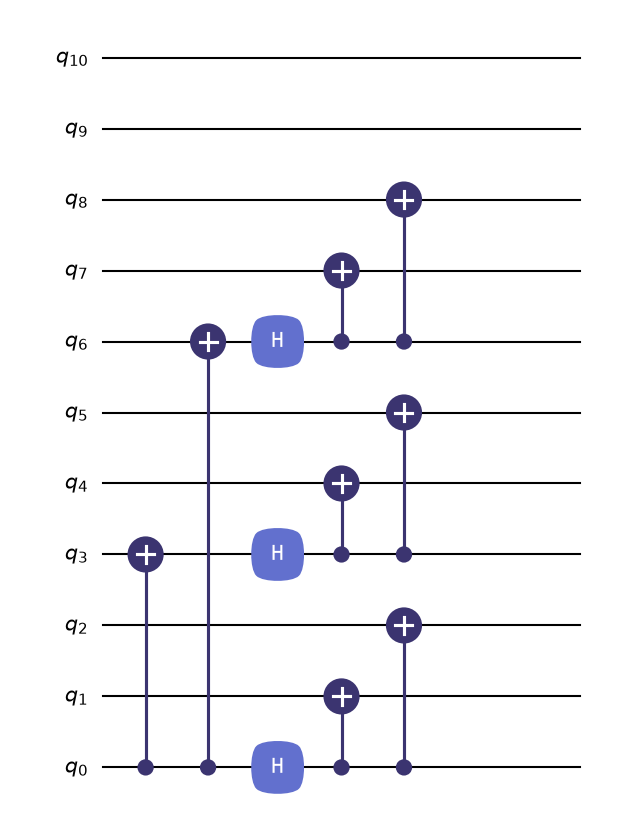

In [124]:
#CIRCUITO CODIFICADOR
qenc = QubitCircuit(11, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[3])
qenc.add_gate("CNOT", controls=[0], targets=[6])

qenc.add_gate("H", targets=[0])
qenc.add_gate("H", targets=[3])
qenc.add_gate("H", targets=[6])


qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
qenc.add_gate("CNOT", controls=[3], targets=[4])
qenc.add_gate("CNOT", controls=[3], targets=[5])
qenc.add_gate("CNOT", controls=[6], targets=[7])
qenc.add_gate("CNOT", controls=[6], targets=[8])

qenc


In [125]:
#ESTADO CODIFICADO
encoded_state = qenc.run(state=state1)
encoded_state

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(2048, 1), type='ket', dtype=Dense
Qobj data =
[[0.47434165]
 [0.        ]
 [0.        ]
 ...
 [0.        ]
 [0.        ]
 [0.        ]]

In [144]:
#GENERAR EL ESTADO CON ERROR FASE O BIT-FLIP
error_op_flip = [qeye(2)]*11
error_op_phase = [qeye(2)]*11
flip_qubit = random.randint(0,8)
phase_qubit = random.randint(0,8)
print("Bit-flipping qubit {}".format(flip_qubit))
print("Phase-flipping qubit {}".format(phase_qubit))

error_op_flip[flip_qubit] *= sigmax()
error_op_phase[phase_qubit] *= sigmaz()

#Error localizado bit-flip
i=1

errorlocalizado_flip = [qeye(2)]*11
errorlocalizado_flip[i] *= sigmax()

#Error localizado phase
j=1

errorlocalizado_phase = [qeye(2)]*11
errorlocalizado_phase[j] *= sigmaz()


#APLICA EL ERROR QUE QUIERAS: errorlocalizado_flip, errorlocalizado_phase, error_op_flip, error_op_phase
errorstate=tensor(error_op_flip) * encoded_state
#AÑADIR OTRO ERROR (diferente tipo al anterior)
errorstate=tensor(error_op_phase) * errorstate

Bit-flipping qubit 1
Phase-flipping qubit 0


In [ ]:
# CIRCUITO CORRECCION CUANTICA FASE
qcorrphase = QubitCircuit(11, reverse_states=False)

# Extracción de síndrome
qcorrphase.add_gate("H", targets=[9])
qcorrphase.add_gate("H", targets=[10])

for i in range(6):
    qcorrphase.add_gate("CNOT", controls=[9], targets=[i])

for i in range(6):
    qcorrphase.add_gate("CNOT", controls=[10], targets=[i+3])

qcorrphase.add_gate("H", targets=[9])
qcorrphase.add_gate("H", targets=[10])

# Síndrome 11: corregir bloque 3-5
for k in [3,4,5]:
    qcorrphase.add_gate("H", targets=[k])
    qcorrphase.add_gate("TOFFOLI", controls=[9,10], targets=[k])
    qcorrphase.add_gate("H", targets=[k])

# Síndrome 01: corregir bloque 6-8
qcorrphase.add_gate("X", targets=[9])

for k in [6,7,8]:
    qcorrphase.add_gate("H", targets=[k])
    qcorrphase.add_gate("TOFFOLI", controls=[9,10], targets=[k])
    qcorrphase.add_gate("H", targets=[k])

qcorrphase.add_gate("X", targets=[9])

# Síndrome 10: corregir bloque 0-2
qcorrphase.add_gate("X", targets=[10])

for k in [0,1,2]:
    qcorrphase.add_gate("H", targets=[k])
    qcorrphase.add_gate("TOFFOLI", controls=[9,10], targets=[k])
    qcorrphase.add_gate("H", targets=[k])

qcorrphase.add_gate("X", targets=[10])



qcorrphase




In [146]:
#CORRIGE QUANTICAMENTE FASE
quantumcorrphase=qcorrphase.run(state=errorstate)
quantumcorrphase

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(2048, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [0.]
 [0.]
 ...
 [0.]
 [0.]
 [0.]]

In [150]:
quantumcorrphase=reset_ancillas(quantumcorrphase)

[[1.+0.j]
 [0.+0.j]
 [0.+0.j]
 [0.+0.j]]
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]]


In [ ]:
qcorrbit012 = QubitCircuit(11, reverse_states=False)

qcorrbit012.add_gate("CNOT", controls=[0], targets=[9])
qcorrbit012.add_gate("CNOT", controls=[1], targets=[9])
qcorrbit012.add_gate("CNOT", controls=[1], targets=[10])
qcorrbit012.add_gate("CNOT", controls=[2], targets=[10])

qcorrbit012.add_gate("TOFFOLI", controls=[9,10], targets=[1])
qcorrbit012.add_gate("X", targets=[9])
qcorrbit012.add_gate("TOFFOLI", controls=[9,10], targets=[2])
qcorrbit012.add_gate("X", targets=[9])
qcorrbit012.add_gate("X", targets=[10])
qcorrbit012.add_gate("TOFFOLI", controls=[9,10], targets=[0])
qcorrbit012.add_gate("X", targets=[10])

qcorrbit012

In [151]:
#CORRIGE QUANTICAMENTE BITFLIP012
quantumcorrbit012=qcorrbit012.run(state=quantumcorrphase)
quantumcorrbit012

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(2048, 1), type='ket', dtype=Dense
Qobj data =
[[0.        ]
 [0.        ]
 [0.        ]
 ...
 [0.        ]
 [0.        ]
 [0.15811388]]

In [152]:
quantumcorrbit012=reset_ancillas(quantumcorrbit012)

[[0.+0.j]
 [0.+0.j]
 [0.+0.j]
 [1.+0.j]]
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]]


In [ ]:
qcorrbit345 = QubitCircuit(11, reverse_states=False)

qcorrbit345.add_gate("CNOT", controls=[3], targets=[9])
qcorrbit345.add_gate("CNOT", controls=[4], targets=[9])
qcorrbit345.add_gate("CNOT", controls=[4], targets=[10])
qcorrbit345.add_gate("CNOT", controls=[5], targets=[10])

qcorrbit345.add_gate("TOFFOLI", controls=[9,10], targets=[4])
qcorrbit345.add_gate("X", targets=[9])
qcorrbit345.add_gate("TOFFOLI", controls=[9,10], targets=[5])
qcorrbit345.add_gate("X", targets=[9])
qcorrbit345.add_gate("X", targets=[10])
qcorrbit345.add_gate("TOFFOLI", controls=[9,10], targets=[3])
qcorrbit345.add_gate("X", targets=[10])

qcorrbit345

In [153]:
#CORRIGE QUANTICAMENTE BITFLIP345
quantumcorrbit345=qcorrbit345.run(state=quantumcorrbit012)
quantumcorrbit345

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(2048, 1), type='ket', dtype=Dense
Qobj data =
[[-0.47434165]
 [ 0.        ]
 [ 0.        ]
 ...
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]]

In [154]:
quantumcorrbit345=reset_ancillas(quantumcorrbit345)

[[1.+0.j]
 [0.+0.j]
 [0.+0.j]
 [0.+0.j]]
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]]


In [ ]:
qcorrbit678 = QubitCircuit(11, reverse_states=False)

qcorrbit678.add_gate("CNOT", controls=[6], targets=[9])
qcorrbit678.add_gate("CNOT", controls=[7], targets=[9])
qcorrbit678.add_gate("CNOT", controls=[7], targets=[10])
qcorrbit678.add_gate("CNOT", controls=[8], targets=[10])

qcorrbit678.add_gate("TOFFOLI", controls=[9,10], targets=[7])
qcorrbit678.add_gate("X", targets=[9])
qcorrbit678.add_gate("TOFFOLI", controls=[9,10], targets=[8])
qcorrbit678.add_gate("X", targets=[9])
qcorrbit678.add_gate("X", targets=[10])
qcorrbit678.add_gate("TOFFOLI", controls=[9,10], targets=[6])
qcorrbit678.add_gate("X", targets=[10])

qcorrbit678

In [155]:
#CORRIGE QUANTICAMENTE BITFLIP678
quantumcorrbit678=qcorrbit678.run(state=quantumcorrbit345)
quantumcorrbit678

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(2048, 1), type='ket', dtype=Dense
Qobj data =
[[-0.47434165]
 [ 0.        ]
 [ 0.        ]
 ...
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]]

In [156]:
quantumcorrbit678=reset_ancillas(quantumcorrbit678)

[[1.+0.j]
 [0.+0.j]
 [0.+0.j]
 [0.+0.j]]
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]]


In [ ]:
#CIRCUITO DECOD
decod=QubitCircuit(11, reverse_states=False)
decod.add_gate("CNOT", controls=[6], targets=[8])
decod.add_gate("CNOT", controls=[6], targets=[7])
decod.add_gate("CNOT", controls=[3], targets=[5])
decod.add_gate("CNOT", controls=[3], targets=[4])
decod.add_gate("CNOT", controls=[0], targets=[2])
decod.add_gate("CNOT", controls=[0], targets=[1])

decod.add_gate("H", targets=[6])
decod.add_gate("H", targets=[3])
decod.add_gate("H", targets=[0])

decod.add_gate("CNOT", controls=[0], targets=[6])
decod.add_gate("CNOT", controls=[0], targets=[3])

decod


In [157]:
#ELEGIR SI DECODIFICAR EL ESTADO CORREGIDO MANUALMENTE O QUANTICAMENTE (manualcorr, quantumcorr)
decoded_state = decod.run(state=quantumcorrbit678)
decoded_state

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(2048, 1), type='ket', dtype=Dense
Qobj data =
[[-0.4472136]
 [ 0.       ]
 [ 0.       ]
 ...
 [ 0.       ]
 [ 0.       ]
 [ 0.       ]]

In [158]:
decoded_state.ptrace(0).eigenstates()

(array([0., 1.]),
 array([Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[-0.89442719]
         [ 0.4472136 ]]                                                       ,
        Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[0.4472136 ]
         [0.89442719]]                                                        ],
       dtype=object))